In [10]:
import pandas as pd
import numpy as np

# Load metadata with two-level headers
tracks = pd.read_csv('../data/fma_metadata/tracks.csv', index_col=0, header=[0, 1])

# Keep only tracks belonging to the 'small' subset
small_tracks = tracks[tracks[('set', 'subset')] == 'small']

# Load extracted audio features with three-level headers
features = pd.read_csv('../data/fma_metadata/features.csv', index_col=0, header=[0, 1, 2])

# Filter features to match only small_tracks
X_small = features.loc[small_tracks.index].dropna()

print(f"Data successfully loaded. Shape: {X_small.shape}")

Data successfully loaded. Shape: (8000, 518)


In [11]:
print("small_tracks shape:", small_tracks.shape)
print("X_small shape:", X_small.shape)

small_tracks shape: (8000, 52)
X_small shape: (8000, 518)


In [13]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# In a pure baseline search space, we fit on the available corpus
scaler.fit(X_small)
X_scaled = scaler.transform(X_small)

X_scaled_df = pd.DataFrame(X_scaled, index=X_small.index, columns=X_small.columns)
print("Scaled features shape:", X_scaled_df.shape)

Scaled features shape: (8000, 518)


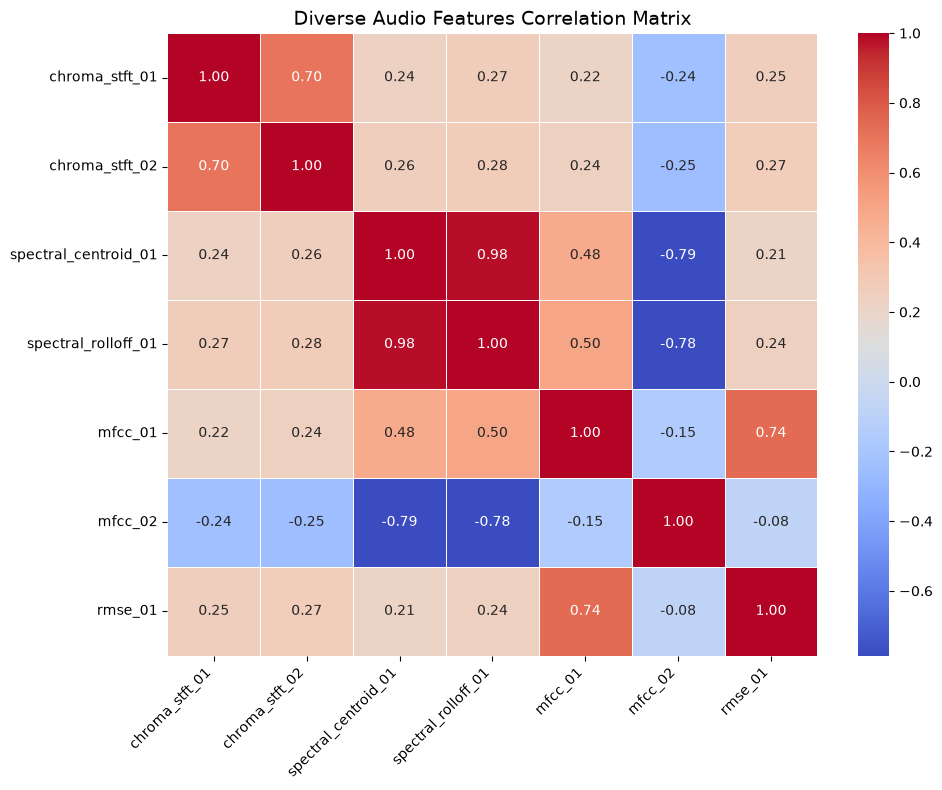

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Explicitly pick 1 feature from each category
target_features = ['chroma_stft', 'spectral_centroid', 'spectral_rolloff', 'mfcc', 'rmse']
selected_cols = []

for feat in target_features:
    matching = [col for col in X_scaled_df.columns if col[0] == feat and col[1] == 'mean']
    if matching:
        selected_cols.extend(matching[:2])  # Take first 2 channels/dimensions of each

df_analysis = X_scaled_df[selected_cols].copy()
df_analysis.columns = [f"{col[0]}_{col[2]}" for col in df_analysis.columns]

# Compute & Plot
plt.figure(figsize=(10, 8))
sns.heatmap(df_analysis.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Diverse Audio Features Correlation Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

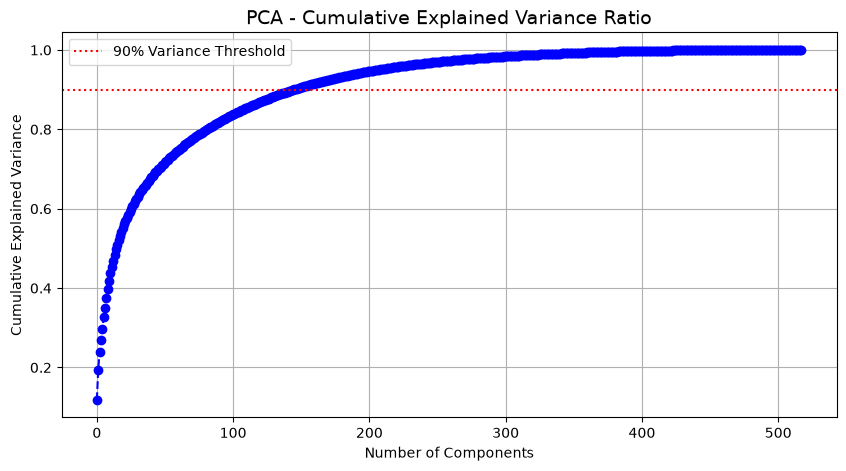

Number of components needed to explain 90% variance: 146


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Fit PCA on scaled data
pca = PCA().fit(X_scaled_df)

# 2. Calculate cumulative explained variance ratio
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# 3. Plot Explained Variance
plt.figure(figsize=(10, 5))
plt.plot(cumulative_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.90, color='r', linestyle=':', label='90% Variance Threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance Ratio', fontsize=14)
plt.grid(True)
plt.legend()
plt.show()

# Print number of components needed for 90% variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"Number of components needed to explain 90% variance: {n_90}")